# Анализ A/B/C-теста email-рассылки (Hillstrom)

## 1. Постановка задачи

### Контекст
Интернет-магазин одежды провёл эксперимент с email-рассылкой. 64 000 клиентов, совершавших
покупки за последние 12 месяцев, были случайным образом разделены на три группы примерно по 21 300 человек:
- **Mens E-Mail** — получили письмо с мужскими товарами;
- **Womens E-Mail** — получили письмо с женскими товарами;
- **No E-Mail** — не получили письма (контрольная группа).

В течение двух недель после рассылки магазин отслеживал, заходил ли каждый клиент на сайт,
совершил ли покупку и сколько потратил.

### Бизнес-вопрос
Стоит ли компании отправлять рассылку, и если да, то какую версию: мужскую или женскую?

### Метрики
| Метрика | Формула | Роль |
|---|---|---|
| Конверсия в покупку | клиенты, совершившие покупку / все клиенты группы | **основная** |
| Доля визитов | клиенты, посетившие сайт / все клиенты группы | вторичная |
| Выручка на клиента | сумма трат в группе / все клиенты группы | вторичная |

**Почему конверсия — основная метрика:** бизнес зарабатывает на покупках, а не на визитах.
Выручка важна, но большинство клиентов тратят 0 USD, поэтому дисперсия высокая и тест по выручке
менее чувствителен. Решение принимается по конверсии; выручка анализируется как вспомогательная метрика.

### Гипотезы
p_M, p_W, p_C — конверсия в покупку во всей генеральной совокупности клиентов при мужском письме,
женском письме и без письма.

| Сравнение | H₀ | H₁ |
|---|---|---|
| Мужское vs контроль | p_M = p_C | p_M ≠ p_C |
| Женское vs контроль | p_W = p_C | p_W ≠ p_C |
| Мужское vs женское | p_M = p_W | p_M ≠ p_W |

### Уровень значимости
- α = 0,05, число сравнений m = 3.
- Поправка Бонферрони: порог для каждого сравнения α / m = 0,05 / 3 ≈ **0,0167**.
  Без поправки вероятность хотя бы одного ложноположительного результата составила бы 1 − 0,95³ ≈ 14%.
- **Двусторонние** тесты: письмо может как повысить, так и снизить конверсию,
  а при сравнении двух писем мы заранее не знаем, какое из них лучше.

### План анализа
2. Проверка качества данных
3. Описательная статистика
4. Проверка рандомизации (SRM, баланс групп)
5. Мощность теста (MDE)
6. Тесты долей: конверсия и визиты
7. Тесты выручки: t-тест, бутстреп, Манна–Уитни
8. Сегментный анализ: какие клиенты реагируют на какое письмо
9. Бизнес-вывод и рекомендация
10. Сравнение с другими анализами

## 2. Проверка качества данных

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from scipy.stats import norm
from statsmodels.stats.proportion import proportions_ztest, confint_proportions_2indep

# русские подписи групп для графиков (значения в данных не меняются)
GROUP_RU = {'No E-Mail': 'Без письма', 'Womens E-Mail': 'Женское письмо', 'Mens E-Mail': 'Мужское письмо'}

In [2]:
df = pd.read_csv('../data/hillstrom.csv')

In [3]:
df.shape

(64000, 12)

In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 64000 entries, 0 to 63999
Data columns (total 12 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   recency          64000 non-null  int64  
 1   history_segment  64000 non-null  str    
 2   history          64000 non-null  float64
 3   mens             64000 non-null  int64  
 4   womens           64000 non-null  int64  
 5   zip_code         64000 non-null  str    
 6   newbie           64000 non-null  int64  
 7   channel          64000 non-null  str    
 8   segment          64000 non-null  str    
 9   visit            64000 non-null  int64  
 10  conversion       64000 non-null  int64  
 11  spend            64000 non-null  float64
dtypes: float64(2), int64(6), str(4)
memory usage: 5.9 MB


In [5]:
df.isna().sum()

recency            0
history_segment    0
history            0
mens               0
womens             0
zip_code           0
newbie             0
channel            0
segment            0
visit              0
conversion         0
spend              0
dtype: int64

In [6]:
df['recency'].between(1, 12).all() # должно быть 1–12 (месяцы в году)

np.True_

In [7]:
df[(df['history'] < 0) | (df['spend'] < 0)]['recency'].count()

np.int64(0)

In [8]:
for col in ['mens', 'womens', 'newbie', 'visit', 'conversion']:
    print(col, df[col].isin([0, 1]).all())

mens True
womens True
newbie True
visit True
conversion True


In [9]:
for col in ['segment', 'zip_code', 'channel', 'history_segment']:
    print(col, list(df[col].unique()))

segment ['Womens E-Mail', 'No E-Mail', 'Mens E-Mail']
zip_code ['Surburban', 'Rural', 'Urban']
channel ['Phone', 'Web', 'Multichannel']
history_segment ['2) $100 - $200', '3) $200 - $350', '5) $500 - $750', '1) $0 - $100', '6) $750 - $1,000', '4) $350 - $500', '7) $1,000 +']


In [10]:
len(df[(df['spend'] > 0) & (df['conversion'] == 0)])

0

In [11]:
len(df[(df['spend'] == 0) & (df['conversion'] == 1)])

0

In [12]:
len(df[(df['visit'] == 0) & (df['conversion'] == 1)])

0

In [13]:
df.duplicated().sum()

np.int64(6562)

### Вывод
- В датасете **64 000 строк и 12 столбцов**; типы данных корректны, **пропусков нет**.
- Все значения в допустимых диапазонах: `recency` от 1 до 12, `history` и `spend` неотрицательны,
  бинарные столбцы содержат только 0 и 1.
- В категориальных столбцах нет неожиданных значений. Примечание: в `zip_code` в исходных данных есть опечатка `Surburban`
  (вместо *Suburban*); она оставлена как есть.
- Данные логически согласованы: `spend > 0` ровно тогда, когда `conversion = 1`,
  и нет покупок без посещения сайта.
- **6 562 строки — точные дубликаты.** Так как ID клиента нет и каждая строка соответствует
  отдельному клиенту, это разные клиенты с одинаковыми признаками, поэтому они сохранены.

**Данные чистые и готовы к анализу.**

## 3. Описательная статистика

In [14]:
grouped_segment = df.groupby('segment').agg(
    customers=('segment', 'count'),
    visit_rate=('visit', 'mean'),
    conversion_rate=('conversion', 'mean'),
    revenue_per_customer=('spend', 'mean')
)
grouped_segment.round(4)

,customers,visit_rate,conversion_rate,revenue_per_customer
segment,,,,
Mens E-Mail,21307,0.1828,0.0125,1.4226
No E-Mail,21306,0.1062,0.0057,0.6528
Womens E-Mail,21387,0.1514,0.0088,1.0772


In [15]:
print(f'{((df['spend'] == 0).mean() * 100).round(2)} % пользователей потратили $0')

99.1 % пользователей потратили $0


In [16]:
(df['spend']).mode()[0]

np.float64(0.0)

In [17]:
grouped_segment_spend = df.groupby('segment').agg(
    customers=('segment', 'count'),
    avg=('spend', 'mean'),
    q25=('spend', lambda x: x.quantile(0.25)),
    q50=('spend', lambda x: x.quantile(0.50)),
    q75=('spend', lambda x: x.quantile(0.75)),
    q90=('spend', lambda x: x.quantile(0.90)),
    q99=('spend', lambda x: x.quantile(0.99)),
)
grouped_segment_spend.round(4)

,customers,avg,q25,q50,q75,q90,q99
segment,,,,,,,
Mens E-Mail,21307,1.4226,0.0,0.0,0.0,0.0,29.99
No E-Mail,21306,0.6528,0.0,0.0,0.0,0.0,0.00
Womens E-Mail,21387,1.0772,0.0,0.0,0.0,0.0,0.00


In [18]:
buyers = df[df['spend'] > 0]

In [19]:
grouped_segment_buyers = buyers.groupby('segment').agg(
    buyers=('segment', 'count'),
    avg=('spend', 'mean'),
    q25=('spend', lambda x: x.quantile(0.25)),
    q50=('spend', lambda x: x.quantile(0.50)),
    q75=('spend', lambda x: x.quantile(0.75)),
    q90=('spend', lambda x: x.quantile(0.90)),
    q99=('spend', lambda x: x.quantile(0.99)),
)
grouped_segment_buyers.round(2)

,buyers,avg,q25,q50,q75,q90,q99
segment,,,,,,,
Mens E-Mail,267,113.53,29.99,66.98,152.72,262.79,499.00
No E-Mail,122,114.00,35.04,88.36,146.17,226.88,487.64
Womens E-Mail,189,121.89,35.20,94.71,163.79,268.04,499.00


In [20]:
buyers[buyers['segment'] == 'Mens E-Mail'].groupby('spend').agg(
    buyers=('spend', 'count')
)

,buyers
spend,
29.99,70
30.24,1
30.94,1
30.98,1
32.17,1
...,...
397.32,1
421.17,1
421.76,1


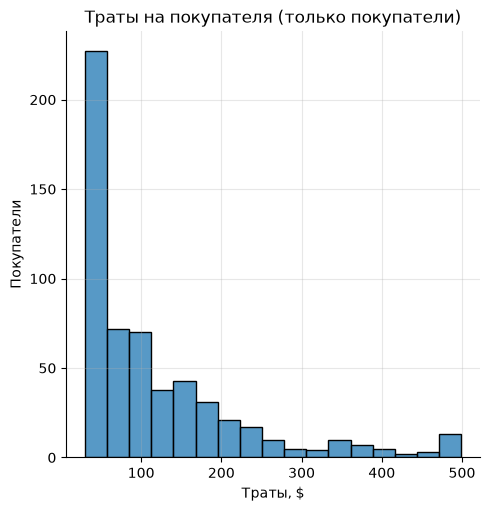

In [21]:
sns.displot(data=buyers, x='spend')
plt.title('Траты на покупателя (только покупатели)')
plt.xlabel('Траты, $')
plt.ylabel('Покупатели')
plt.grid(axis='both', alpha=0.3)
plt.show()

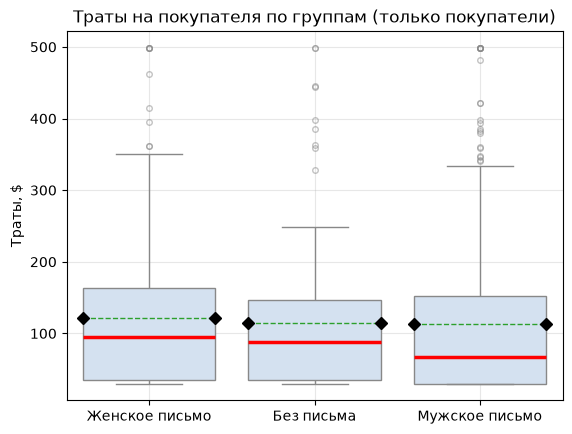

In [22]:
sns.boxplot(data=buyers, x='segment', y='spend', 
            color='#cfe0f5',
            medianprops=dict(color='red', linewidth=2.5),
            flierprops=dict(marker='o', markersize=4, alpha=0.5),
            showmeans=True,
            meanline=True, 
            meanprops=dict(marker='D', markerfacecolor='black', markeredgecolor='black', markersize=6)
           )
plt.xticks(plt.xticks()[0], [GROUP_RU[t.get_text()] for t in plt.gca().get_xticklabels()])
plt.title('Траты на покупателя по группам (только покупатели)')
plt.xlabel('')
plt.ylabel('Траты, $')
plt.grid(axis='both', alpha=0.3)
plt.show()

### Вывод

**Метрики по группам** (только описательно, значимость проверяется на шаге 6):

| Группа | Доля визитов | Конверсия | Выручка на клиента |
|---|---|---|---|
| Mens E-Mail | 18,3% | 1,25% | 1,42 USD |
| Womens E-Mail | 15,1% | 0,88% | 1,08 USD |
| No E-Mail | 10,6% | 0,57% | 0,65 USD |

Оба письма показывают более высокие значения, чем контрольная группа; мужское письмо — самое высокое по всем трём метрикам.

- **99,1% клиентов ничего не купили** за время теста: мода `spend` равна 0,
  и все перцентили до 90-го включительно равны 0.
- **578 клиентов совершили покупку.** Их средний заказ — 114–122 USD, медиана — 67–95 USD,
  с длинным правым хвостом до 499 USD.
- У мужского письма больше всего покупателей (267), но **самая низкая медиана заказа (67 USD)**:
  26% его покупок — ровно 29,99 USD, против примерно 21% в других группах.
- **Особенности данных:** много покупок ровно на 29,99 USD, и 12 покупателей потратили ровно 499 USD —
  максимальное значение, так что `spend`, возможно, ограничен 499 USD в исходных данных.

## 4. Проверка рандомизации

In [23]:
grouped_segment_history = df.groupby('segment').agg(
    avg=('history', 'mean'),
    q25=('history', lambda x: x.quantile(0.25)),
    q50=('history', lambda x: x.quantile(0.50)),
    q75=('history', lambda x: x.quantile(0.75)),
    q90=('history', lambda x: x.quantile(0.90)),
    q99=('history', lambda x: x.quantile(0.99)),
)
grouped_segment_history.round(2)

,avg,q25,q50,q75,q90,q99
segment,,,,,,
Mens E-Mail,242.84,63.58,157.22,325.22,563.63,1229.96
No E-Mail,240.88,65.30,156.66,325.17,561.06,1191.89
Womens E-Mail,242.54,65.04,160.09,326.82,558.16,1239.73


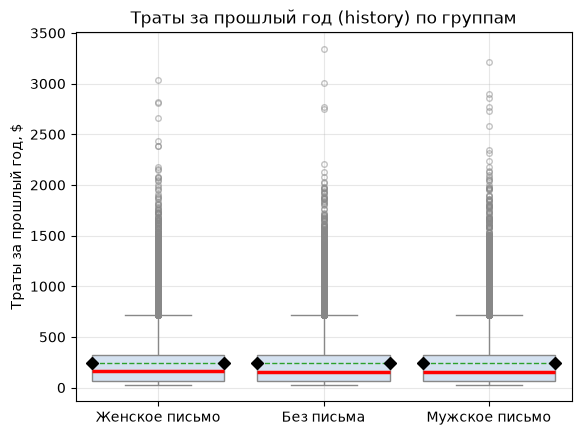

In [24]:
sns.boxplot(data=df, x='segment', y='history', 
            color='#cfe0f5',
            medianprops=dict(color='red', linewidth=2.5),
            flierprops=dict(marker='o', markersize=4, alpha=0.5),
            showmeans=True,
            meanline=True, 
            meanprops=dict(marker='D', markerfacecolor='black', markeredgecolor='black', markersize=6)
            )
plt.xticks(plt.xticks()[0], [GROUP_RU[t.get_text()] for t in plt.gca().get_xticklabels()])
plt.title('Траты за прошлый год (history) по группам')
plt.xlabel('')
plt.ylabel('Траты за прошлый год, $')
plt.grid(axis='both', alpha=0.3)
plt.show()

In [25]:
crosstab_channel = pd.crosstab(df['segment'], df['channel'], normalize='index')

crosstab_channel.round(4)

channel,Multichannel,Phone,Web
segment,,,
Mens E-Mail,0.1209,0.4337,0.4454
No E-Mail,0.1223,0.4378,0.4399
Womens E-Mail,0.1206,0.4420,0.4374


In [26]:
crosstab_zip_code = pd.crosstab(df['segment'], df['zip_code'], normalize='index')

crosstab_zip_code.round(4)

zip_code,Rural,Surburban,Urban
segment,,,
Mens E-Mail,0.1522,0.4459,0.4019
No E-Mail,0.1473,0.4518,0.4009
Womens E-Mail,0.1487,0.4512,0.4001


In [27]:
crosstab_history_segment = pd.crosstab(df['segment'], df['history_segment'], normalize='index')

crosstab_history_segment.round(4)

history_segment,1) $0 - $100,2) $100 - $200,3) $200 - $350,4) $350 - $500,5) $500 - $750,"6) $750 - $1,000","7) $1,000 +"
segment,,,,,,,
Mens E-Mail,0.3625,0.2202,0.1920,0.0984,0.0750,0.0302,0.0218
No E-Mail,0.3573,0.2270,0.1898,0.0997,0.0775,0.0292,0.0195
Womens E-Mail,0.3569,0.2210,0.1943,0.1023,0.0777,0.0277,0.0200


In [28]:
crosstab_newbie = pd.crosstab(df['segment'], df['newbie'], normalize='index')

crosstab_newbie.round(4)

newbie,0,1
segment,,
Mens E-Mail,0.4985,0.5015
No E-Mail,0.4980,0.5020
Womens E-Mail,0.4968,0.5032


In [29]:
n = len(df)
p0 = 1/3
SE = np.sqrt(p0 * (1 - p0) / n)
print(f'Доля должна быть между {(1/3 - SE).round(4)} и {(1/3 + SE).round(4)}')
rows = []
for key, value in df['segment'].value_counts().items():
    p_hat = value / n
    z = (p_hat - p0) / SE
    rows.append({
        'segment': key,
        'n': value,
        'share': p_hat,
        'z': z,
        'p_value': 2 * norm.sf(abs(z)),
        'p_value_binom': stats.binomtest(value, n, p0).pvalue
    })
print(pd.DataFrame(rows).round(4))

print('p-value всех групп больше 0.001, поэтому SRM нет')

Доля должна быть между 0.3315 и 0.3352
         segment      n   share       z  p_value  p_value_binom
0  Womens E-Mail  21387  0.3342  0.4500   0.6527         0.6537
1    Mens E-Mail  21307  0.3329 -0.2208   0.8252         0.8274
2      No E-Mail  21306  0.3329 -0.2292   0.8187         0.8209
p-value всех групп больше 0.001, поэтому SRM нет


In [30]:
df.groupby('segment')[['recency', 'history', 'newbie', 'mens', 'womens']].mean().round(4)

,recency,history,newbie,mens,womens
segment,,,,,
Mens E-Mail,5.7736,242.8359,0.5015,0.5509,0.5514
No E-Mail,5.7497,240.8827,0.5020,0.5532,0.5476
Womens E-Mail,5.7678,242.5366,0.5032,0.5489,0.5501


### Вывод

**Нет sample ratio mismatch (SRM).** Доля каждой группы проверялась против ожидаемой 1/3:

| Группа | Клиентов | Доля | p-value (z-тест) | p-value (биномиальный) |
|---|---|---|---|---|
| Womens E-Mail | 21 387 | 33,42% | 0,653 | 0,654 |
| Mens E-Mail | 21 307 | 33,29% | 0,825 | 0,827 |
| No E-Mail | 21 306 | 33,29% | 0,819 | 0,821 |

Все p-value намного выше порога 0,001. z-тест (нормальное приближение)
и точный биномиальный тест дают почти одинаковые результаты.

**Группы сбалансированы по признакам клиентов до теста:**
- `recency`: среднее 5,75–5,77 месяца во всех группах;
- `history`: среднее 240,9–242,8 USD, медиана 156,7–160,1 USD (различия меньше 1%);
- `newbie`, `mens`, `womens`, `channel`, `zip_code`, `history_segment`:
  доли различаются между группами меньше чем на 1 процентный пункт.

**Рандомизация сработала:** группы различаются только полученным письмом,
поэтому различия в метриках теста можно приписать письму.

## 5. Мощность теста (MDE)

In [31]:
control = df[df['segment'] == 'No E-Mail']
n = len(control)
alpha = 0.05 / 3
power = 0.8
z_alpha = norm.ppf(1 - alpha / 2)
z_power = norm.ppf(power)
for metric in ['conversion', 'visit']:
    p = control[metric].mean()
    SE = np.sqrt(2 * p * (1 - p) / n)
    MDE = (z_alpha + z_power) * SE
    print(f'{metric}: база {p * 100:.2f}%, MDE {MDE * 100:.3f} п.п. '
          f'({MDE / p * 100:.1f}% относительно)')

conversion: база 0.57%, MDE 0.237 п.п. (41.3% относительно)
visit: база 10.62%, MDE 0.966 п.п. (9.1% относительно)


### Вывод

MDE рассчитан для каждого письма против контроля (двусторонний тест, α = 0,05 / 3 ≈ 0,0167,
мощность 80%, около 21 300 клиентов в группе, контрольная группа как базовый уровень):

| Метрика | Значение в контроле | MDE (абсолютный) | MDE (относительный) |
|---|---|---|---|
| Конверсия | 0,57% | 0,237 п.п. (~50 покупателей на группу) | 41,3% |
| Доля визитов | 10,62% | 0,966 п.п. | 9,1% |

- Тест надёжно обнаруживает только **большие** изменения конверсии: около +41% относительно
  контроля (или такое же снижение). Меньшие эффекты могут быть пропущены, поэтому незначимый результат
  означал бы «тест слишком мал, чтобы увидеть эффект», а не «письмо не работает».
- Для визитов тест гораздо чувствительнее (MDE 9,1%), потому что доля визитов намного выше
  конверсии.
- Для сравнения мужского и женского писем MDE немного больше, потому что базовая конверсия
  в группах с письмами выше, чем в контрольной.

## 6. Тесты долей: конверсия и визиты

### Попарные сравнения

Каждое письмо сравнивается с контрольной группой, а два письма сравниваются между собой.
Разница всегда считается как **группа B − группа A**, поэтому положительное значение означает, что в группе B показатель выше.

- **z-тест:** SE использует объединённую долю p̂ (мир H₀, где обе доли равны).
- **Доверительный интервал:** SE использует доли двух групп по отдельности.
- Интервал использует z = 2,394 (а не 1,96), поэтому он соответствует порогу Бонферрони 0,0167:
  если интервал не содержит 0, разница значима.

In [32]:
alpha = 0.05 / 3
z_crit = norm.ppf(1 - alpha / 2)    # 2.394

pairs = [('No E-Mail', 'Mens E-Mail'),
         ('No E-Mail', 'Womens E-Mail'),
         ('Womens E-Mail', 'Mens E-Mail')]
metrics = ['conversion', 'visit']

rows = []
for group_a, group_b in pairs:
    a = df[df['segment'] == group_a]
    b = df[df['segment'] == group_b]
    for metric in metrics:
        x_a, n_a = a[metric].sum(), len(a)
        x_b, n_b = b[metric].sum(), len(b)
        p_a, p_b = x_a / n_a, x_b / n_b
        diff = p_b - p_a

        # z-тест: объединённая SE (мир H0)
        p_pool = (x_a + x_b) / (n_a + n_b)
        se_test = np.sqrt(p_pool * (1 - p_pool) * (1 / n_a + 1 / n_b))
        z = diff / se_test
        p_value = 2 * norm.sf(abs(z))

        # доверительный интервал: раздельная SE
        se_ci = np.sqrt(p_a * (1 - p_a) / n_a + p_b * (1 - p_b) / n_b)

        rows.append({
            'metric': metric,
            'group_a': group_a,
            'group_b': group_b,
            'rate_a_%': p_a * 100,
            'rate_b_%': p_b * 100,
            'diff_pp': diff * 100,
            'relative_%': diff / p_a * 100,
            'ci_low_pp': (diff - z_crit * se_ci) * 100,
            'ci_high_pp': (diff + z_crit * se_ci) * 100,
            'z': z,
            'p_value': p_value,
            'significant': p_value <= alpha,
        })

prop_results = pd.DataFrame(rows)

# в prop_results p-value хранятся как числа; форматирование только для отображения
display_props = prop_results.round(3)
display_props['p_value'] = prop_results['p_value'].apply(lambda p: '< 0.001' if p < 0.001 else f'{p:.3f}')
display_props

,metric,group_a,group_b,rate_a_%,rate_b_%,diff_pp,relative_%,ci_low_pp,ci_high_pp,z,p_value,significant
0,conversion,No E-Mail,Mens E-Mail,0.573,1.253,0.681,118.842,0.460,0.901,7.385,< 0.001,True
1,visit,No E-Mail,Mens E-Mail,10.617,18.276,7.659,72.140,6.848,8.470,22.486,< 0.001,True
2,conversion,No E-Mail,Womens E-Mail,0.573,0.884,0.311,54.331,0.114,0.508,3.780,< 0.001,True
3,visit,No E-Mail,Womens E-Mail,10.617,15.140,4.523,42.606,3.749,5.298,13.949,< 0.001,True
4,conversion,Womens E-Mail,Mens E-Mail,0.884,1.253,0.369,41.800,0.131,0.608,3.713,< 0.001,True
5,visit,Womens E-Mail,Mens E-Mail,15.140,18.276,3.136,20.711,2.272,3.999,8.685,< 0.001,True


**Проверка через statsmodels.** Ручной z-тест и интервал должны совпадать с `proportions_ztest`
и `confint_proportions_2indep(method='wald')`.

In [33]:
checks = []
for _, row in prop_results.iterrows():
    a = df[df['segment'] == row['group_a']][row['metric']]
    b = df[df['segment'] == row['group_b']][row['metric']]
    z_sm, p_sm = proportions_ztest([b.sum(), a.sum()], [len(b), len(a)])
    ci_low, ci_high = confint_proportions_2indep(b.sum(), len(b), a.sum(), len(a),
                                                 method='wald', alpha=alpha)
    checks.append({
        'metric': row['metric'],
        'group_a': row['group_a'],
        'group_b': row['group_b'],
        'z_diff': abs(z_sm - row['z']),
        'ci_low_diff': abs(ci_low * 100 - row['ci_low_pp']),
        'ci_high_diff': abs(ci_high * 100 - row['ci_high_pp']),
    })

pd.DataFrame(checks)    # все разницы должны быть ~0

,metric,group_a,group_b,z_diff,ci_low_diff,ci_high_diff
0,conversion,No E-Mail,Mens E-Mail,0.0,1.665335e-16,1.110223e-16
1,visit,No E-Mail,Mens E-Mail,0.0,0.000000e+00,0.000000e+00
2,conversion,No E-Mail,Womens E-Mail,0.0,8.326673e-17,1.110223e-16
3,visit,No E-Mail,Womens E-Mail,0.0,8.881784e-16,0.000000e+00
4,conversion,Womens E-Mail,Mens E-Mail,0.0,8.326673e-17,1.110223e-16
5,visit,Womens E-Mail,Mens E-Mail,0.0,4.440892e-16,0.000000e+00


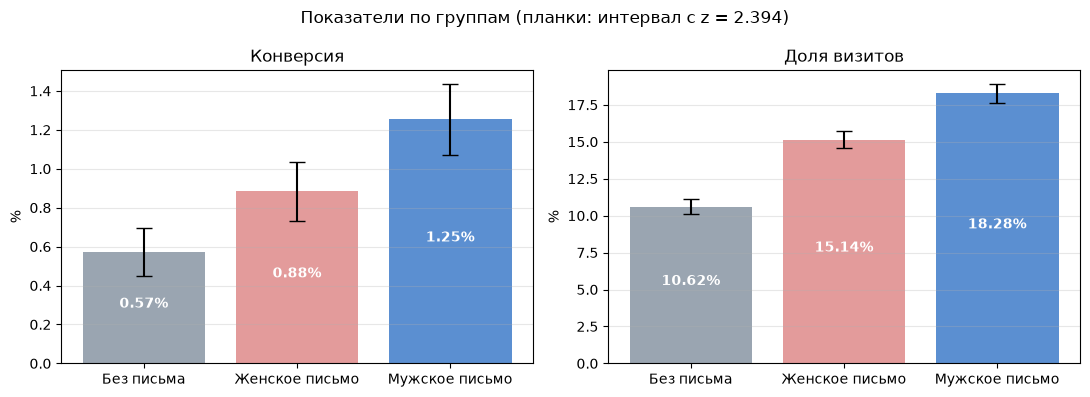

In [34]:
order = ['No E-Mail', 'Womens E-Mail', 'Mens E-Mail']
colors = ['#9aa5b1', '#e39b9b', '#5b8fd1']

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, metric, title in zip(axes, ['conversion', 'visit'], ['Конверсия', 'Доля визитов']):
    rates, errors = [], []
    for group in order:
        x = df[df['segment'] == group][metric]
        p = x.mean()
        rates.append(p * 100)
        errors.append(z_crit * np.sqrt(p * (1 - p) / len(x)) * 100)   # интервал для доли каждой группы
    ax.bar([GROUP_RU[g] for g in order], rates, yerr=errors, capsize=6, color=colors)
    for i, r in enumerate(rates):
        ax.text(i, r / 2, f'{r:.2f}%', ha='center', color='white', fontweight='bold')
    ax.set_title(title)
    ax.set_ylabel('%')
    ax.grid(axis='y', alpha=0.3)

plt.suptitle('Показатели по группам (планки: интервал с z = 2.394)')
plt.tight_layout()
plt.savefig('../images/rates_by_group.png', dpi=150, bbox_inches='tight')
plt.show()

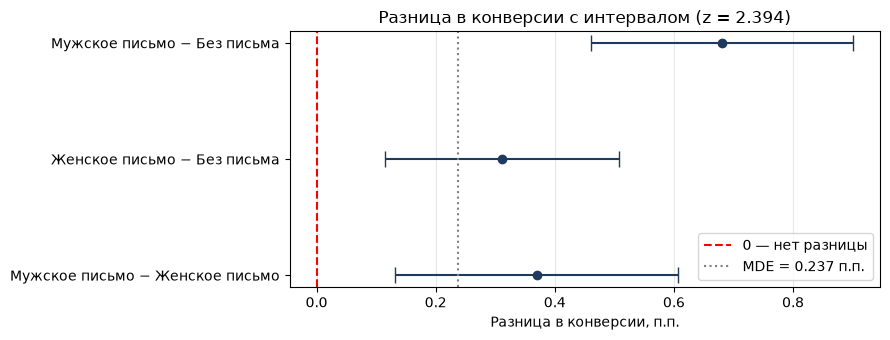

In [35]:
# разницы в конверсии с доверительными интервалами в сравнении с MDE из шага 5
conv = prop_results[prop_results['metric'] == 'conversion'].reset_index(drop=True)
labels = [f"{GROUP_RU[b]} − {GROUP_RU[a]}" for a, b in zip(conv['group_a'], conv['group_b'])]
mde_pp = 0.237    # MDE из шага 5 (письмо vs контроль)

fig, ax = plt.subplots(figsize=(9, 3.5))
ax.errorbar(conv['diff_pp'], range(len(conv)),
            xerr=[conv['diff_pp'] - conv['ci_low_pp'], conv['ci_high_pp'] - conv['diff_pp']],
            fmt='o', color='#1f3a5f', capsize=6)
ax.axvline(0, color='red', linestyle='--', label='0 — нет разницы')
ax.axvline(mde_pp, color='grey', linestyle=':', label=f'MDE = {mde_pp} п.п.')
ax.set_yticks(range(len(conv)))
ax.set_yticklabels(labels)
ax.invert_yaxis()
ax.set_xlabel('Разница в конверсии, п.п.')
ax.set_title('Разница в конверсии с интервалом (z = 2.394)')
ax.legend(loc='lower right')
ax.grid(axis='x', alpha=0.3)
plt.tight_layout()
plt.savefig('../images/conversion_differences.png', dpi=150, bbox_inches='tight')
plt.show()

### Вывод

**Все шесть сравнений значимы** при пороге Бонферрони 0,0167 (все p-value < 0,001).

| Сравнение | Конверсия | Разница, п.п. (относительная) | Интервал, п.п. | Визиты | Разница, п.п. (относительная) | Интервал, п.п. |
|---|---|---|---|---|---|---|
| Mens − No E-Mail | 1,253% vs 0,573% | **+0,68** (+119%) | от 0,46 до 0,90 | 18,28% vs 10,62% | **+7,66** (+72%) | от 6,85 до 8,47 |
| Womens − No E-Mail | 0,884% vs 0,573% | **+0,31** (+54%) | от 0,11 до 0,51 | 15,14% vs 10,62% | **+4,52** (+43%) | от 3,75 до 5,30 |
| Mens − Womens | 1,253% vs 0,884% | **+0,37** (+42%) | от 0,13 до 0,61 | 18,28% vs 15,14% | **+3,14** (+21%) | от 2,27 до 4,00 |

- **Оба письма работают.** Каждое письмо увеличивает и визиты, и конверсию по сравнению с отсутствием письма.
- **Мужское письмо сильнее женского** по обеим метрикам: +0,37 п.п. конверсии и +3,14 п.п. визитов.
- Все наблюдаемые разницы в конверсии больше MDE из шага 5 (0,237 п.п.), так что мощности теста хватило, чтобы их обнаружить.
- Ни один интервал не содержит 0, что согласуется с p-value.
- Ручные расчёты совпадают со `statsmodels` (разницы ≈ 0).

Примечание: на столбчатой диаграмме планки погрешностей двух групп с письмами пересекаются, но разница между ними всё равно значима.
Пересечение интервалов двух отдельных групп не означает «нет разницы» — проверять нужно саму разницу, как в таблице выше.

## 7. Тесты выручки

Выручка на клиента (`spend`) сильно скошена: 99,1% клиентов потратили 0, а несколько человек — до 499 USD.
Разница средних проверяется тремя методами:

| Метод | Что сравнивает | Зачем |
|---|---|---|
| t-тест Уэлча | средние | стандартный тест для выручки; при n ≈ 21 000 среднее распределено примерно нормально |
| Бутстреп | средние | интервал без допущений о форме распределения данных |
| Манна–Уитни | распределения целиком | устойчив к выбросам, но отвечает на другой вопрос (не о средних) |

SE для t-теста и интервала: √(s_A²/n_A + s_B²/n_B). Интервал использует z = 2,394, как на шаге 6.

In [36]:
rng = np.random.default_rng(42)    # фиксированный seed: результаты бутстрепа воспроизводимы
n_boot = 10_000

rows = []
boot_diffs = {}
for group_a, group_b in pairs:
    a = df[df['segment'] == group_a]['spend'].values
    b = df[df['segment'] == group_b]['spend'].values
    diff = b.mean() - a.mean()

    # t-тест Уэлча вручную
    se = np.sqrt(a.var(ddof=1) / len(a) + b.var(ddof=1) / len(b))
    t = diff / se
    p_value = 2 * norm.sf(abs(t))                       # n большое: t-распределение ≈ z
    p_scipy = stats.ttest_ind(b, a, equal_var=False).pvalue

    # бутстреп-интервал для разницы средних
    diffs = np.array([rng.choice(b, size=len(b)).mean() - rng.choice(a, size=len(a)).mean()
                      for _ in range(n_boot)])
    boot_low, boot_high = np.percentile(diffs, [alpha / 2 * 100, (1 - alpha / 2) * 100])
    boot_diffs[(group_a, group_b)] = diffs

    # Манна–Уитни
    p_mw = stats.mannwhitneyu(b, a, alternative='two-sided').pvalue

    rows.append({
        'group_a': group_a,
        'group_b': group_b,
        'mean_a': a.mean(),
        'mean_b': b.mean(),
        'diff': diff,
        'relative_%': diff / a.mean() * 100,
        't': t,
        'p_welch': p_value,
        'p_welch_scipy': p_scipy,
        'ci_low': diff - z_crit * se,
        'ci_high': diff + z_crit * se,
        'boot_low': boot_low,
        'boot_high': boot_high,
        'p_mann_whitney': p_mw,
        'significant_welch': p_value <= alpha,
    })

revenue_results = pd.DataFrame(rows)
revenue_results.round(4)

,group_a,group_b,mean_a,mean_b,diff,relative_%,t,p_welch,p_welch_scipy,ci_low,ci_high,boot_low,boot_high,p_mann_whitney,significant_welch
0,No E-Mail,Mens E-Mail,0.6528,1.4226,0.7698,117.9289,5.3001,0.0000,0.0000,0.4221,1.1175,0.4177,1.1210,0.0000,True
1,No E-Mail,Womens E-Mail,0.6528,1.0772,0.4244,65.0152,3.2564,0.0011,0.0011,0.1124,0.7364,0.1181,0.7384,0.0002,True
2,Womens E-Mail,Mens E-Mail,1.0772,1.4226,0.3454,32.0660,2.1640,0.0305,0.0305,-0.0367,0.7275,-0.0397,0.7229,0.0002,False


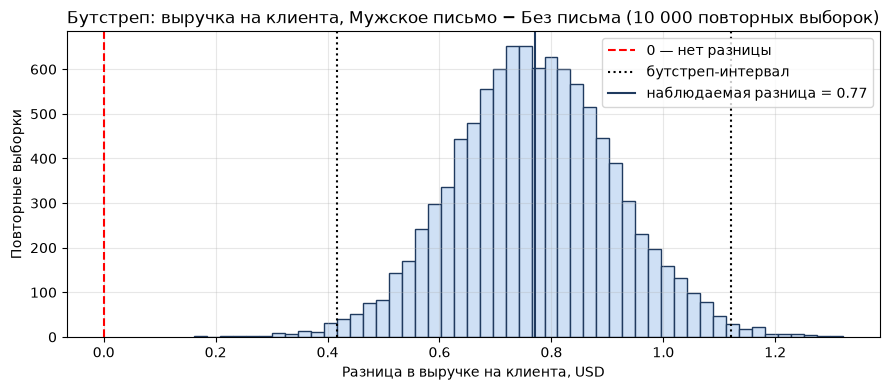

In [37]:
diffs = boot_diffs[('No E-Mail', 'Mens E-Mail')]
row = revenue_results.iloc[0]

plt.figure(figsize=(9, 4))
plt.hist(diffs, bins=50, color='#cfe0f5', edgecolor='#1f3a5f')
plt.axvline(0, color='red', linestyle='--', label='0 — нет разницы')
plt.axvline(row['boot_low'], color='black', linestyle=':', label='бутстреп-интервал')
plt.axvline(row['boot_high'], color='black', linestyle=':')
plt.axvline(row['diff'], color='#1f3a5f', label=f"наблюдаемая разница = {row['diff']:.2f}")
plt.title('Бутстреп: выручка на клиента, Мужское письмо − Без письма (10 000 повторных выборок)')
plt.xlabel('Разница в выручке на клиента, USD')
plt.ylabel('Повторные выборки')
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig('../images/bootstrap_mens_vs_control.png', dpi=150, bbox_inches='tight')
plt.show()

**Откуда берётся рост выручки?** Выручка на клиента = конверсия × средний чек (AOV).
Если средний чек у покупателей не меняется, весь рост идёт за счёт большего числа покупателей.

In [38]:
rows = []
for group_a, group_b in pairs:
    a = buyers[buyers['segment'] == group_a]['spend']
    b = buyers[buyers['segment'] == group_b]['spend']
    rows.append({
        'group_a': group_a,
        'group_b': group_b,
        'buyers_a': len(a),
        'buyers_b': len(b),
        'aov_a': a.mean(),
        'aov_b': b.mean(),
        'aov_diff': b.mean() - a.mean(),
        'p_welch': stats.ttest_ind(b, a, equal_var=False).pvalue,
        'p_mann_whitney': stats.mannwhitneyu(b, a, alternative='two-sided').pvalue,
    })

aov_results = pd.DataFrame(rows)
aov_results.round(3)

,group_a,group_b,buyers_a,buyers_b,aov_a,aov_b,aov_diff,p_welch,p_mann_whitney
0,No E-Mail,Mens E-Mail,122,267,114.003,113.527,-0.476,0.967,0.321
1,No E-Mail,Womens E-Mail,122,189,114.003,121.895,7.892,0.515,0.509
2,Womens E-Mail,Mens E-Mail,189,267,121.895,113.527,-8.368,0.417,0.097


### Вывод

| Сравнение | Выручка на клиента | Разница (относительная) | p-value Уэлча | Интервал (Уэлч) | Интервал (бутстреп) | p-value Манна–Уитни |
|---|---|---|---|---|---|---|
| Mens − No E-Mail | 1,42 vs 0,65 USD | **+0,77 USD** (+118%) | < 0,001 | от 0,42 до 1,12 | от 0,42 до 1,12 | < 0,001 |
| Womens − No E-Mail | 1,08 vs 0,65 USD | **+0,42 USD** (+65%) | 0,001 | от 0,11 до 0,74 | от 0,12 до 0,74 | < 0,001 |
| Mens − Womens | 1,42 vs 1,08 USD | +0,35 USD (+32%) | 0,031 | от −0,04 до 0,73 | от −0,04 до 0,72 | < 0,001 |

- **Оба письма значимо увеличивают выручку на клиента** по сравнению с отсутствием письма.
- **Мужское vs женское письмо: разница в выручке не значима** при пороге 0,0167 (p = 0,031, оба интервала содержат 0).
  Мужское письмо, вероятно, лучше (оно лучше по конверсии и визитам), но данные по выручке слишком шумные, чтобы это доказать.
- **Уэлч и бутстреп согласуются** (интервалы различаются только во втором знаке после запятой), так что при ~21 000 клиентов в группе t-тест работает даже для такой сильно скошенной метрики.
- **Манна–Уитни даёт другой ответ для Mens − Womens** (p < 0,001). При 99% нулей он в основном сравнивает долю покупателей, которая уже проверена на шаге 6,
  а не среднюю выручку. Поэтому для решения по выручке он не используется.
- **Средний чек (AOV) не меняется**: 114 USD в контроле против 114 USD (мужское письмо) и 122 USD (женское письмо), все p-value > 0,4.
  Выручка на клиента = конверсия × AOV, поэтому **весь рост выручки идёт за счёт большего числа покупателей, а не более крупных заказов.**

## 8. Сегментный анализ

**Вопрос:** работает ли каждое письмо для всех клиентов или только для некоторых?

Сегменты были выбраны **до** того, как мы посмотрели на результаты:

| Сегмент | Значения |
|---|---|
| `newbie` | существующий / новый клиент |
| `purchase_history` (из `mens`, `womens`) | покупал только мужское / только женское / оба |
| `channel` | Phone / Web / Multichannel |
| `zip_code` | Urban / Surburban / Rural |
| `history_level` | траты за прошлый год ниже медианы / не ниже медианы |

Каждое письмо сравнивается с контрольной группой внутри каждого значения сегмента:
13 значений × 2 письма = **26 сравнений**, поэтому порог Бонферрони 0,05 / 26 ≈ **0,0019**.
Метрика: конверсия (основная).

Сегменты намного меньше целых групп, поэтому мощность ниже:
незначимый результат в сегменте не доказывает, что письмо там не работает.

In [39]:
df['purchase_history'] = np.select(
    [(df['mens'] == 1) & (df['womens'] == 0), (df['mens'] == 0) & (df['womens'] == 1)],
    ['mens only', 'womens only'],
    default='both',
)
df['history_level'] = np.where(df['history'] >= df['history'].median(), 'high', 'low')
df['newbie_label'] = df['newbie'].map({0: 'existing', 1: 'new'})

segment_columns = {
    'newbie': 'newbie_label',
    'purchase_history': 'purchase_history',
    'channel': 'channel',
    'zip_code': 'zip_code',
    'history_level': 'history_level',
}
emails = ['Mens E-Mail', 'Womens E-Mail']

n_comparisons = sum(df[col].nunique() for col in segment_columns.values()) * len(emails)
alpha_seg = 0.05 / n_comparisons
z_seg = norm.ppf(1 - alpha_seg / 2)
print(f'{n_comparisons} сравнений, порог = {alpha_seg:.4f}, z = {z_seg:.3f}')

rows = []
for segment, col in segment_columns.items():
    for value in sorted(df[col].unique()):
        part = df[df[col] == value]
        a = part[part['segment'] == 'No E-Mail']['conversion']
        for email in emails:
            b = part[part['segment'] == email]['conversion']
            x_a, n_a, x_b, n_b = a.sum(), len(a), b.sum(), len(b)
            p_a, p_b = x_a / n_a, x_b / n_b
            p_pool = (x_a + x_b) / (n_a + n_b)
            se_test = np.sqrt(p_pool * (1 - p_pool) * (1 / n_a + 1 / n_b))
            se_ci = np.sqrt(p_a * (1 - p_a) / n_a + p_b * (1 - p_b) / n_b)
            z = (p_b - p_a) / se_test
            p_value = 2 * norm.sf(abs(z))
            rows.append({
                'segment': segment,
                'value': value,
                'email': email,
                'n_control': n_a,
                'n_email': n_b,
                'conv_control_%': p_a * 100,
                'conv_email_%': p_b * 100,
                'diff_pp': (p_b - p_a) * 100,
                'ci_low_pp': (p_b - p_a - z_seg * se_ci) * 100,
                'ci_high_pp': (p_b - p_a + z_seg * se_ci) * 100,
                'p_value': p_value,
                'significant': p_value <= alpha_seg,
            })

segment_results = pd.DataFrame(rows)
segment_results.round(4)

26 сравнений, порог = 0.0019, z = 3.102


,segment,value,email,n_control,n_email,conv_control_%,conv_email_%,diff_pp,ci_low_pp,ci_high_pp,p_value,significant
0,newbie,existing,Mens E-Mail,10611,10621,0.7728,1.3935,0.6207,0.1802,1.0611,0.0000,True
1,newbie,existing,Womens E-Mail,10611,10624,0.7728,0.8660,0.0932,-0.2906,0.4769,0.4514,False
2,newbie,new,Mens E-Mail,10695,10686,0.3740,1.1136,0.7396,0.3754,1.1038,0.0000,True
3,newbie,new,Womens E-Mail,10695,10763,0.3740,0.9012,0.5272,0.1905,0.8639,0.0000,True
4,purchase_history,both,Mens E-Mail,2149,2181,0.9307,2.4301,1.4994,0.2916,2.7072,0.0001,True
5,purchase_history,both,Womens E-Mail,2149,2118,0.9307,1.4636,0.5330,-0.5004,1.5664,0.1092,False
6,purchase_history,mens only,Mens E-Mail,9638,9558,0.5499,1.1509,0.6010,0.1897,1.0122,0.0000,True
7,purchase_history,mens only,Womens E-Mail,9638,9622,0.5499,0.6132,0.0633,-0.2766,0.4032,0.5637,False
8,purchase_history,womens only,Mens E-Mail,9519,9568,0.5148,1.0870,0.5722,0.1723,0.9720,0.0000,True
9,purchase_history,womens only,Womens E-Mail,9519,9647,0.5148,1.0262,0.5115,0.1202,0.9027,0.0001,True


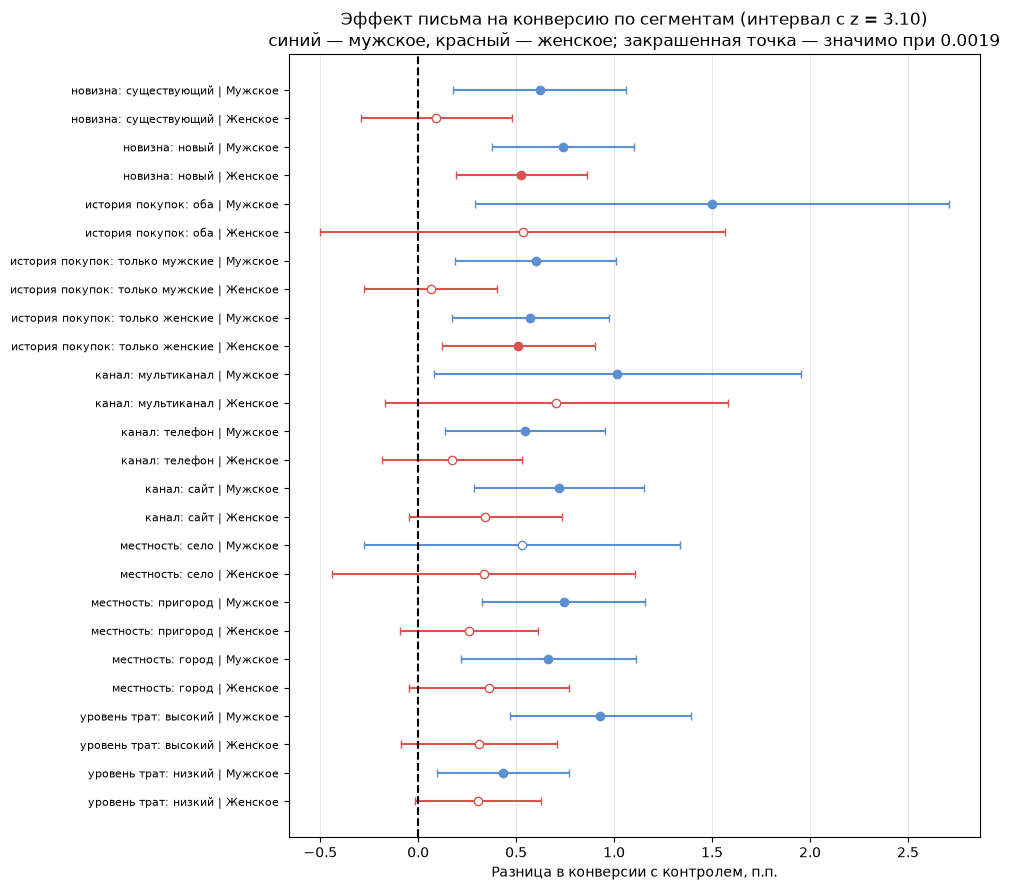

In [40]:
SEG_RU = {'newbie': 'новизна', 'purchase_history': 'история покупок', 'channel': 'канал',
          'zip_code': 'местность', 'history_level': 'уровень трат'}
VAL_RU = {'existing': 'существующий', 'new': 'новый', 'both': 'оба', 'mens only': 'только мужские',
          'womens only': 'только женские', 'Multichannel': 'мультиканал', 'Phone': 'телефон', 'Web': 'сайт',
          'Rural': 'село', 'Surburban': 'пригород', 'Urban': 'город', 'high': 'высокий', 'low': 'низкий'}
EMAIL_SHORT_RU = {'Mens E-Mail': 'Мужское', 'Womens E-Mail': 'Женское'}

fig, ax = plt.subplots(figsize=(10, 9))
labels = []
for i, (_, row) in enumerate(segment_results.iterrows()):
    color = '#5b8fd1' if row['email'] == 'Mens E-Mail' else '#d9534f'
    face = color if row['significant'] else 'white'    # закрашенная точка = значимо
    ax.errorbar(row['diff_pp'], i,
                xerr=[[row['diff_pp'] - row['ci_low_pp']], [row['ci_high_pp'] - row['diff_pp']]],
                fmt='o', color=color, markerfacecolor=face, capsize=3)
    labels.append(f"{SEG_RU[row['segment']]}: {VAL_RU[row['value']]} | {EMAIL_SHORT_RU[row['email']]}")

ax.axvline(0, color='black', linestyle='--')
ax.set_yticks(range(len(labels)))
ax.set_yticklabels(labels, fontsize=8)
ax.invert_yaxis()
ax.set_xlabel('Разница в конверсии с контролем, п.п.')
ax.set_title(f'Эффект письма на конверсию по сегментам (интервал с z = {z_seg:.2f})\n'
             'синий — мужское, красный — женское; закрашенная точка — значимо при 0.0019')
ax.grid(axis='x', alpha=0.3)
plt.tight_layout()
plt.savefig('../images/segments_conversion.png', dpi=150, bbox_inches='tight')
plt.show()

**Описательный взгляд по истории покупок:** конверсия и выручка на клиента для всех трёх групп.

In [41]:
by_history = df.pivot_table(index='purchase_history', columns='segment',
                            values=['conversion', 'spend'], aggfunc='mean')
by_history['conversion'] = by_history['conversion'] * 100
by_history.round(2)

conversion                               spend            \
segment          Mens E-Mail No E-Mail Womens E-Mail Mens E-Mail No E-Mail   
purchase_history                                                             
both                    2.43      0.93          1.46        3.01      1.18   
mens only               1.15      0.55          0.61        1.38      0.70   
womens only             1.09      0.51          1.03        1.11      0.49   

                                
segment          Womens E-Mail  
purchase_history                
both                      1.34  
mens only                 0.97  
womens only               1.12

### Вывод

26 сравнений, порог Бонферрони 0,0019. Результаты по сегментам носят **исследовательский** характер: сегменты меньше, поэтому мощность ниже,
и незначимый результат не доказывает отсутствие эффекта.

**Мужское письмо: работает почти везде.** Оно значимо в 12 из 13 значений сегментов; исключение — Rural (+0,53 п.п., p = 0,043, всего около 3 200 клиентов в группе).
Наибольший прирост:
- клиенты, покупавшие **и** мужские, и женские товары: +1,50 п.п. (0,93% → 2,43%)
- **мультиканальные** клиенты: +1,02 п.п. (0,69% → 1,71%)
- клиенты с **высокими тратами за прошлый год**: +0,93 п.п. (0,73% → 1,66%)

Оно также работает для клиентов, покупавших **только женские товары** (+0,57 п.п.).

**Женское письмо: работает только в двух сегментах.**
- **новые клиенты**: +0,53 п.п. (0,37% → 0,90%)
- клиенты, покупавшие **только женские товары**: +0,51 п.п. (0,51% → 1,03%)

Для существующих клиентов (+0,09 п.п.) и клиентов, покупавших только мужские товары (+0,06 п.п.), заметного эффекта нет.

**Покупатели только женских товаров — единственная группа, где два письма близки:**
конверсия 1,09% (мужское письмо) против 1,03% (женское письмо), выручка на клиента 1,11 против 1,12 USD.
Во всех остальных сегментах мужское письмо впереди.

## 9. Бизнес-вывод

**Инкрементальный эффект на 1 000 писем** = (метрика с письмом − метрика в контроле) × 1 000.
Выручка в этом датасете — это продажи, а не прибыль, поэтому для оценки прибыли нужны два допущения.
Они заданы как параметры ниже и могут быть изменены.

In [42]:
margin = 0.40                 # допущение: валовая маржа интернет-магазина одежды
cost_per_1000_emails = 10     # допущение: стоимость отправки 1 000 писем, USD

control = df[df['segment'] == 'No E-Mail']
rows = []
for email in ['Mens E-Mail', 'Womens E-Mail']:
    group = df[df['segment'] == email]
    extra_visitors = (group['visit'].mean() - control['visit'].mean()) * 1000
    extra_buyers = (group['conversion'].mean() - control['conversion'].mean()) * 1000
    extra_revenue = (group['spend'].mean() - control['spend'].mean()) * 1000
    rev = revenue_results[(revenue_results['group_a'] == 'No E-Mail') &
                          (revenue_results['group_b'] == email)].iloc[0]
    rows.append({
        'email': email,
        'extra_visitors': extra_visitors,
        'extra_buyers': extra_buyers,
        'extra_revenue_usd': extra_revenue,
        'revenue_ci_low_usd': rev['ci_low'] * 1000,
        'revenue_ci_high_usd': rev['ci_high'] * 1000,
        'extra_profit_usd': extra_revenue * margin - cost_per_1000_emails,
        'profit_worst_case_usd': rev['ci_low'] * 1000 * margin - cost_per_1000_emails,
    })

impact = pd.DataFrame(rows).set_index('email')
print('На 1 000 отправленных писем:')
impact.round(1)

На 1 000 отправленных писем:


,extra_visitors,extra_buyers,extra_revenue_usd,revenue_ci_low_usd,revenue_ci_high_usd,extra_profit_usd,profit_worst_case_usd
email,,,,,,,
Mens E-Mail,76.6,6.8,769.8,422.1,1117.5,297.9,158.8
Womens E-Mail,45.2,3.1,424.4,112.4,736.4,159.8,35.0


### Вывод

**На 1 000 отправленных писем** (разница с отсутствием письма):

| | Мужское письмо | Женское письмо |
|---|---|---|
| Дополнительные посетители | +77 | +45 |
| Дополнительные покупатели | +6,8 | +3,1 |
| Дополнительная выручка | **+770 USD** (от 422 до 1 118) | **+424 USD** (от 112 до 736) |
| Дополнительная прибыль (маржа 40% − 10 USD на отправку) | +298 USD | +160 USD |
| Прибыль на нижней границе интервала | +159 USD | +35 USD |

**Решение.** Оба письма окупаются даже на нижней границе интервала, а мужское письмо приносит примерно в 1,8 раза больше выручки.

**Рекомендация:**
1. **Отправлять мужское письмо всем клиентам.** Оно сильнее всех по визитам, конверсии и выручке и работает почти во всех сегментах, включая покупателей только женских товаров.
2. Не использовать женское письмо как основную рассылку. Возможно, стоит провести отдельный тест только для **новых клиентов** и **покупателей только женских товаров**, где оно работает примерно так же хорошо, как мужское.
3. Следующий тест: новая версия женского письма (другие товары, предложение или тема письма), так как на существующих клиентов оно не действует.

**Ограничения:**
- **Нет guardrail-метрик**: нет данных об отписках и жалобах на спам, поэтому долгосрочная цена дополнительных писем неизвестна.
- **Только две недели** результатов: неизвестно, сохраняется ли эффект или клиенты просто купили раньше, чем купили бы без письма.
- Выручка — это **продажи, а не прибыль**: маржа (40%) и стоимость отправки (10 USD за 1 000) — допущения.
- `spend` в датасете ограничен 499 USD.
- Данные **2008 года**; поведение клиентов и email-каналы с тех пор изменились.
- Сегментный анализ носит исследовательский характер, и для подтверждения нужен отдельный тест.

## 10. Сравнение с другими анализами

Этот шаг выполнен **после** нашего собственного анализа, поэтому чужие выводы не повлияли на результаты.

**Источники:**
- Kevin Hillstrom, [The MineThatData E-Mail Analytics And Data Mining Challenge](https://blog.minethatdata.com/2008/03/minethatdata-e-mail-analytics-and-data.html) (2008) — датасет и вопросы конкурса.
- Nicholas Radcliffe, Stochastic Solutions, [Hillstrom's MineThatData Email Analytics Challenge: An Approach Using Uplift Modelling](https://www.stochasticsolutions.com/pdf/HillstromChallenge.pdf) (2008) — победившее решение конкурса.

**Общие результаты: в точности совпадают.**

| Метрика (разница с отсутствием письма) | Наш анализ: мужское | Stochastic Solutions: мужское | Наш анализ: женское | Stochastic Solutions: женское |
|---|---|---|---|---|
| Визиты, п.п. | +7,66 | +7,66 | +4,52 | +4,52 |
| Конверсия, п.п. | +0,68 | +0,68 | +0,31 | +0,31 |
| Выручка на клиента, USD | +0,77 | +0,77 | +0,42 | +0,42 |
| Средний чек у покупателей, USD | −0,48 | −0,50 | +7,89 | +7,89 |

Оба анализа приходят к выводу, что мужское письмо лучшее, а рост выручки идёт за счёт большего числа покупателей, а не более крупных заказов.

**Сегменты: то же направление, другой метод.**
- Stochastic Solutions также обнаружили, что мужское письмо лучше всего работает для **мультиканальных клиентов с высокими тратами за прошлый год** (более 350 USD).
  Мы получили то же самое: наибольший прирост у Multichannel (+1,02 п.п.) и у высокого history (+0,93 п.п.).
- Они обнаружили, что женское письмо работает для **новых клиентов** и для клиентов с высокими прошлыми тратами и даже даёт отрицательный эффект для клиентов с прошлыми тратами 200–400 USD.
  Мы обнаружили, что женское письмо работает для новых клиентов и покупателей только женских товаров; отрицательных эффектов мы не увидели, так как использовали более широкие сегменты (ниже / выше медианы).

**Главное различие.** Stochastic Solutions использовали **uplift-моделирование** (модель, предсказывающую эффект письма для каждого клиента),
чтобы выбрать, каким клиентам отправлять письмо. Мы использовали **попарные тесты по сегментам** с поправкой Бонферрони.
Uplift-моделирование может находить более узкие целевые группы, но авторы сами предупреждают, что оценки на уровне сегментов нестабильны при таком малом числе покупателей (конверсия около 1%).
Наш подход проще и консервативнее: он сообщает только о тех эффектах в сегментах, которые достаточно сильны, чтобы пережить 26 сравнений.

**Что добавляет наш анализ:** формальные тесты значимости и доверительные интервалы для каждого сравнения,
проверку мощности (MDE) и вывод о том, что разница между двумя письмами значима по конверсии и визитам, но **не по выручке**.

## Экспорт

Таблицы с результатами сохраняются в `outputs/`. Заголовки столбцов переведены на русский, значения в данных (названия групп и сегментов) оставлены как в исходном датасете.

In [43]:
# русские заголовки столбцов для CSV; внутри ноутбука используются английские имена
COLS_RU = {
    'customers': 'клиенты', 'visit_rate': 'доля_визитов', 'conversion_rate': 'конверсия',
    'revenue_per_customer': 'выручка_на_клиента',
    'metric': 'метрика', 'group_a': 'группа_a', 'group_b': 'группа_b',
    'rate_a_%': 'доля_a_%', 'rate_b_%': 'доля_b_%', 'diff_pp': 'разница_пп', 'relative_%': 'относительно_%',
    'ci_low_pp': 'ди_нижн_пп', 'ci_high_pp': 'ди_верх_пп', 'p_value': 'p_значение', 'significant': 'значимо',
    'mean_a': 'среднее_a', 'mean_b': 'среднее_b', 'diff': 'разница',
    'p_welch': 'p_уэлч', 'p_welch_scipy': 'p_уэлч_scipy', 'ci_low': 'ди_нижн', 'ci_high': 'ди_верх',
    'boot_low': 'бутстреп_нижн', 'boot_high': 'бутстреп_верх', 'p_mann_whitney': 'p_манн_уитни',
    'significant_welch': 'значимо_уэлч',
    'value': 'значение', 'email': 'письмо', 'n_control': 'n_контроль', 'n_email': 'n_письмо',
    'conv_control_%': 'конв_контроль_%', 'conv_email_%': 'конв_письмо_%',
    'extra_visitors': 'доп_посетители', 'extra_buyers': 'доп_покупатели',
    'extra_revenue_usd': 'доп_выручка_usd', 'revenue_ci_low_usd': 'выручка_ди_нижн_usd',
    'revenue_ci_high_usd': 'выручка_ди_верх_usd', 'extra_profit_usd': 'доп_прибыль_usd',
    'profit_worst_case_usd': 'прибыль_худший_случай_usd',
}

def save(table, name, extra=None):
    # utf-8-sig, чтобы Excel правильно открывал кириллицу
    table.rename(columns={**COLS_RU, **(extra or {})}).to_csv(f'../outputs/{name}', index=False, encoding='utf-8-sig')

save(grouped_segment.reset_index(), 'group_summary.csv', {'segment': 'группа'})
save(prop_results, 'proportion_tests.csv')
save(revenue_results, 'revenue_tests.csv')
save(segment_results, 'segment_results.csv', {'segment': 'сегмент'})
save(impact.reset_index(), 'business_impact.csv')
print('сохранено')

сохранено
